# Лабораторная работа 3. Элементарный перцептрон. Ансамбль элементарных перцептронов.

> **Задание 9 (стр. 115).** Реализуйте программно алгоритм обучения элементарного перцептрона для
> распознавания растровых изображений. Можете использовать следующие варианты реализации:
>
> а) 10 элементарных перцептронов, классифицирующих цифры как цифры двух классов: эта цифра/другая цифра;
>
> б) один перцептрон, вместо ступенчатой функции использующий в качестве функции активации функцию
> мягкого максимума, обучаемый с помощью стохастического градиентного спуска.
>
> Может быть использована обучающая выборка для заданий 3 и 4 главы 3.6 «Задания» раздела «Метод ближайшего соседа».
>
> **Задание 10 (стр. 115).** Сформируйте ансамбль из обученных элементарных перцептронов из предыдущего
> задания. Сравните для одной и той же выборки результаты классификации растровых изображений с
> результатами, полученными методом ближайшего соседа и с помощью отдельного классификатора из предыдущего задания.

Реализован вариант а).

## 1. Настройка окружения

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 20261016
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

TABLE_STYLE = [
    {"selector": "", "props": "border-collapse: collapse"},
    {"selector": "th, td", "props": "border: 1px solid #999; padding: 3px 8px; text-align: center"},
    {"selector": "caption", "props": "caption-side: top; font-weight: bold; padding-bottom: 4px"},
]

def show(df, title):
    # Таблица с сеткой и заголовком: значения с одним знаком после запятой, ℓ — как есть
    display(df.style.set_caption(title).set_table_styles(TABLE_STYLE).format(precision=1)
            .format_index(lambda v: f"{v:g}" if isinstance(v, float) else v, axis=0))

## 2. Выборка

Эталоны цифр $8 \times 8$ и равномерное зашумление — из лабораторной работы 1 (задание 4 главы 3), бинарные
изображения и изображения в градациях серого. Яркость нормирована в $[0, 1]$, чтобы признаки были соизмеримы
с $x_0 = 1$: к пикселю полутонового изображения добавляется $\varepsilon \sim \mathsf U[-\ell, \ell]$ с обрезкой до $[0, 1]$,
пиксель бинарного инвертируется с вероятностью $\min(\ell / 2, 1/2)$.

In [2]:
DIGIT_ART = {
    0: ["..####..", ".#....#.", "#......#", "#......#", "#......#", "#......#", ".#....#.", "..####.."],
    1: ["...##...", "..###...", ".####...", "#..##...", "...##...", "...##...", "...##...", "########"],
    2: [".######.", "#......#", ".......#", "......#.", "....##..", "..##....", ".#......", "########"],
    3: [".######.", "#......#", ".......#", "..#####.", ".......#", ".......#", "#......#", ".######."],
    4: ["....##..", "...#.#..", "..#..#..", ".#...#..", "#....#..", "########", ".....#..", ".....#.."],
    5: ["########", "#.......", "#.......", "#######.", ".......#", ".......#", "#......#", ".######."],
    6: [".######.", "#.......", "#.......", "#######.", "#......#", "#......#", "#......#", ".######."],
    7: ["########", ".......#", "......#.", ".....#..", "....#...", "...#....", "..#.....", "..#....."],
    8: [".######.", "#......#", "#......#", ".######.", "#......#", "#......#", "#......#", ".######."],
    9: [".######.", "#......#", "#......#", "#......#", ".#######", ".......#", "......#.", ".#####.."],
}
N_CLASSES = len(DIGIT_ART)
PROTO_BIN = np.array([[[ch == "#" for ch in row] for row in DIGIT_ART[c]] for c in DIGIT_ART], dtype=float)
H, W = PROTO_BIN.shape[1:]

# Полутоновые эталоны: штрих + его среднее по окрестности 3x3, растяжение на [0, 1]
_pad = np.pad(PROTO_BIN, ((0, 0), (1, 1), (1, 1)))
_box = sum(_pad[:, i:i + H, j:j + W] for i in range(3) for j in range(3)) / 9
PROTO = {"binary": PROTO_BIN, "gray": (PROTO_BIN + _box) / (PROTO_BIN + _box).max()}
TYPE_NAMES = {"binary": "бинарные", "gray": "градации серого"}

def add_noise(images, level, image_type, rng):
    if image_type == "gray":
        return np.clip(images + rng.uniform(-level, level, images.shape), 0, 1)
    flip = rng.random(images.shape) < min(level / 2, 0.5)
    return np.where(flip, 1 - images, images)

def make_sample(n_per_class, level, image_type, rng):
    # n_per_class зашумлённых копий каждого эталона: X (n, 64), y (n,)
    X = add_noise(np.repeat(PROTO[image_type], n_per_class, axis=0), level, image_type, rng)
    return X.reshape(len(X), H * W), np.repeat(np.arange(N_CLASSES), n_per_class)

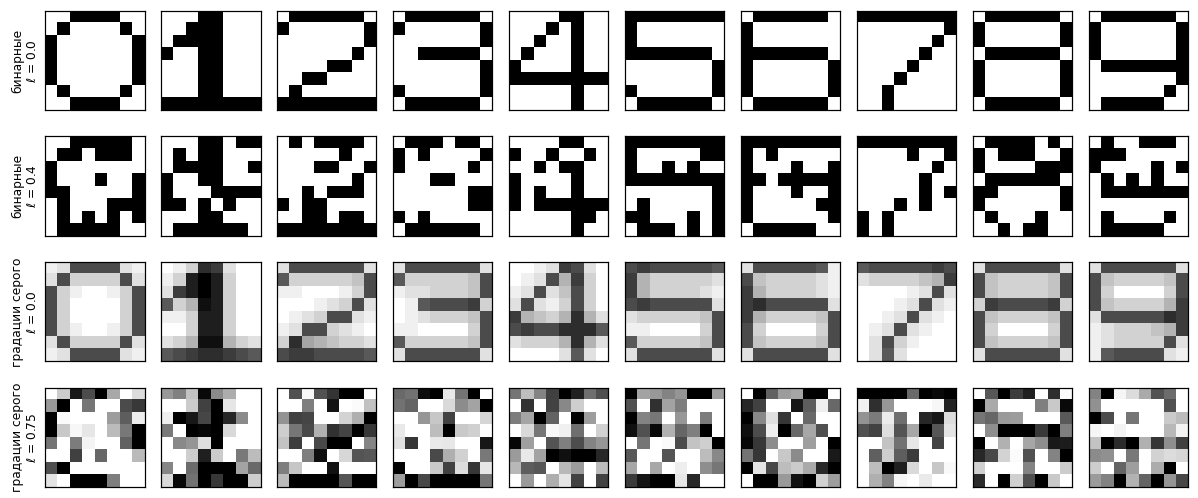

In [3]:
# Примеры: строка — тип изображения и уровень шума, столбец — цифра
demo = [("binary", 0.0), ("binary", 0.4), ("gray", 0.0), ("gray", 0.75)]
fig, axes = plt.subplots(len(demo), N_CLASSES, figsize=(11, 4.8))
for row, (itype, level) in enumerate(demo):
    X, _ = make_sample(1, level, itype, np.random.default_rng(SEED))
    for c, ax in enumerate(axes[row]):
        ax.imshow(X[c].reshape(H, W), cmap="gray_r", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    axes[row, 0].set_ylabel(f"{TYPE_NAMES[itype]}\n$\\ell$ = {level}", fontsize=8)
plt.tight_layout()
plt.show()

## 3. Задание 9. Элементарный перцептрон

Перцептрон вычисляет $y = \theta(\langle w, x \rangle)$, $x_0 = 1$ (стр. 90).
Алгоритм обучения (стр. 92): $w(0) = 0$, векторы выборки перебираются циклически, при неверной классификации
$w := w + \eta x(n)$ для $x(n) \in \mathcal H_1$ и $w := w - \eta x(n)$ для $x(n) \in \mathcal H_2$; остановка — после полного
прохода по выборке без изменений $w$.

Перцептрон цифры $c$ обучается на $\mathcal H_1$ — изображениях цифры $c$ и $\mathcal H_2$ — остальных цифрах. При $w(0) = 0$
веса — сумма слагаемых $\pm\eta x(n)$, поэтому $\eta$ лишь масштабирует $w$ и не меняет классификацию; берём $\eta = 1$.
Для линейно-неотделимой выборки алгоритм не сходится (стр. 95), поэтому число проходов ограничено. Ответ $+1$
даётся при $\langle w, x \rangle > 0$, как в условии на $\tilde w$ (стр. 91): при $\langle w, x \rangle = 0$ алгоритм считает
вектор принадлежащим $\mathcal H_2$, а $\theta(0) = 1$, и на бинарных изображениях такие нули встречаются.

In [4]:
def augment(X):
    # Добавление x_0 = 1
    return np.hstack([np.ones((len(X), 1)), X])

def train_perceptron(X, t, eta=1.0, max_epochs=1000):
    # Алгоритм обучения перцептрона (стр. 92); t = +1 для H1, -1 для H2
    Xa = augment(X)
    w = np.zeros(Xa.shape[1])
    n_corr = 0
    for epoch in range(1, max_epochs + 1):
        changed = False
        for x, t_n in zip(Xa, t):
            s = x @ w
            if t_n == 1 and s <= 0:
                w += eta * x
            elif t_n == -1 and s > 0:
                w -= eta * x
            else:
                continue
            changed = True
            n_corr += 1
        if not changed:
            return w, {"проходов": epoch, "исправлений": n_corr, "сошёлся": True}
    return w, {"проходов": max_epochs, "исправлений": n_corr, "сошёлся": False}

def train_all(X, y):
    # 10 перцептронов «цифра c / другая цифра»: матрица весов (10, 65) и статистика обучения
    ws, stats = zip(*(train_perceptron(X, np.where(y == c, 1, -1)) for c in range(N_CLASSES)))
    return np.array(ws), pd.DataFrame(stats).rename_axis("цифра")

def perceptron_outputs(Ws, X):
    # Ответы всех перцептронов: матрица (n, 10) из +1 (<w_c, x> > 0) / -1
    return np.where(augment(X) @ Ws.T > 0, 1, -1)

### 3.1. Обучение

Обучающая выборка — 30 зашумлённых копий каждого эталона с теми же уровнями шума, что в лабораторной работе 1:
$\ell = 0{,}2$ для бинарных изображений и $\ell = 0{,}3$ для полутоновых.

In [5]:
IMAGE_TYPES = ["binary", "gray"]
LEVEL_TRAIN = {"binary": 0.2, "gray": 0.3}

train, WS, stats = {}, {}, {}
for itype in IMAGE_TYPES:
    train[itype] = make_sample(30, LEVEL_TRAIN[itype], itype, np.random.default_rng(SEED))
    WS[itype], st = train_all(*train[itype])
    X, y = train[itype]
    st["ошибок на обучении"] = (perceptron_outputs(WS[itype], X) != np.where(y[:, None] == np.arange(N_CLASSES), 1, -1)).sum(axis=0)
    stats[TYPE_NAMES[itype]] = st
show(pd.concat(stats, axis=1), "Обучение 10 перцептронов")

Веса $w_1, \ldots, w_{64}$ перцептронов в виде изображений $8 \times 8$: красные пиксели увеличивают $\langle w_c, x \rangle$
(голосуют за цифру $c$), синие — уменьшают.

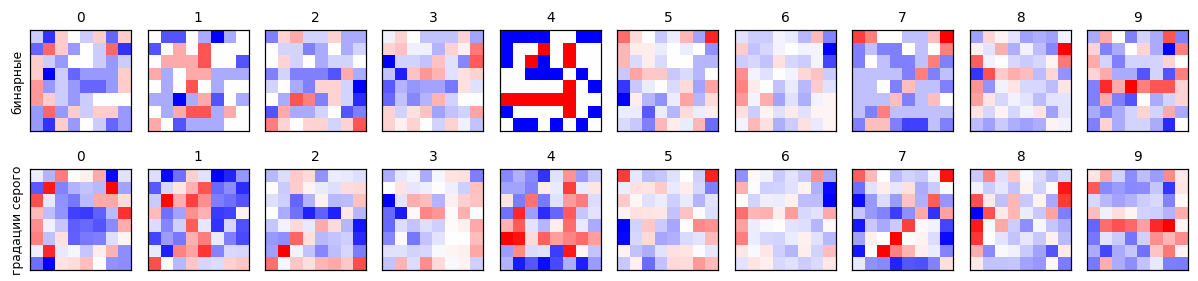

In [6]:
fig, axes = plt.subplots(2, N_CLASSES, figsize=(11, 2.8))
for row, itype in enumerate(IMAGE_TYPES):
    for c, ax in enumerate(axes[row]):
        w = WS[itype][c, 1:].reshape(H, W)
        lim = np.abs(w).max()
        ax.imshow(w, cmap="bwr", vmin=-lim, vmax=lim)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(str(c), fontsize=9)
    axes[row, 0].set_ylabel(TYPE_NAMES[itype], fontsize=8)
plt.tight_layout()
plt.show()

### 3.2. Распознавание отдельными перцептронами

Тестовые выборки — по 50 копий каждого эталона на каждом уровне шума; они же используются в задании 10. Для
перцептрона цифры $c$ считаем две доли: свои изображения, получившие ответ $+1$, и чужие, ошибочно получившие $+1$.

In [7]:
LEVELS = {"binary": [0.0, 0.2, 0.4, 0.6, 0.8, 1.0], "gray": [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]}
test = {(itype, level): make_sample(50, level, itype, np.random.default_rng(SEED + 1 + i))
        for i, (itype, level) in enumerate((t, l) for t in IMAGE_TYPES for l in LEVELS[t])}

def binary_rates(answer_pos, y):
    # answer_pos (n, 10): ответ «это цифра c»; доли своих с ответом +1 и чужих с ответом +1, по цифрам
    own = y[:, None] == np.arange(N_CLASSES)
    return (answer_pos & own).sum(0) / own.sum(0), (answer_pos & ~own).sum(0) / (~own).sum(0)

rows = []
for (itype, level), (X, y) in test.items():
    own, foreign = binary_rates(perceptron_outputs(WS[itype], X) == 1, y)
    rows += [{"тип": TYPE_NAMES[itype], "ℓ": level, "цифра": c, "свои +1, %": 100 * own[c],
              "чужие +1, %": 100 * foreign[c]} for c in range(N_CLASSES)]
single = pd.DataFrame(rows)
show(single.groupby(["тип", "ℓ"])[["свои +1, %", "чужие +1, %"]].mean(), "Отдельные перцептроны, среднее по 10 цифрам")

In [8]:
show(single[single["ℓ"].isin([0.4, 0.75])].pivot_table(index="цифра", columns="тип", values=["свои +1, %", "чужие +1, %"]),
     "Отдельные перцептроны по цифрам: ℓ = 0,4 для бинарных, ℓ = 0,75 для полутоновых")

## 4. Задание 10. Ансамбль перцептронов

Ансамбль относит изображение к цифре, перцептрон которой даёт наибольшее расстояние со знаком до своей
разделяющей гиперплоскости (1): $\hat c(x) = \arg\max_c \langle w_c, x \rangle / \|w_c\|$, норма — без смещения $w_0$.
Деление на норму нужно, потому что перцептроны сделали разное число исправлений и длины $w_c$ различаются. Если
$+1$ выдал ровно один перцептрон, ответ ансамбля совпадает с ним.

На тех же обучающей и тестовых выборках сравниваются:

* **отдельные перцептроны** — ответ есть, только если $+1$ выдал ровно один перцептрон, иначе отказ (считается ошибкой);
* **ансамбль**;
* **метод ближайшего соседа** — $k = 1$, евклидово расстояние (лабораторная работа 1).

In [9]:
def ensemble_predict(Ws, X):
    return np.argmax(augment(X) @ Ws.T / np.linalg.norm(Ws[:, 1:], axis=1), axis=1)

def separate_predict(Ws, X):
    # Класс единственного перцептрона с ответом +1, иначе -1 (отказ)
    pos = perceptron_outputs(Ws, X) == 1
    return np.where(pos.sum(1) == 1, np.argmax(pos, axis=1), -1)

def nn_predict(X_train, y_train, X):
    d2 = (X ** 2).sum(1)[:, None] - 2 * X @ X_train.T + (X_train ** 2).sum(1)[None, :]
    return y_train[np.argmin(d2, axis=1)]

METHODS = {
    "отдельные перцептроны": lambda itype, X: separate_predict(WS[itype], X),
    "ансамбль": lambda itype, X: ensemble_predict(WS[itype], X),
    "ближайший сосед": lambda itype, X: nn_predict(*train[itype], X),
}

rows = []
for (itype, level), (X, y) in test.items():
    for name, predict in METHODS.items():
        pred = predict(itype, X)
        own, foreign = binary_rates(pred[:, None] == np.arange(N_CLASSES), y)
        rows.append({"тип": TYPE_NAMES[itype], "ℓ": level, "метод": name, "точность, %": 100 * np.mean(pred == y),
                     "отказов, %": 100 * np.mean(pred == -1), "свои +1, %": 100 * own.mean(),
                     "чужие +1, %": 100 * foreign.mean()})
res = pd.DataFrame(rows)
show(res.pivot_table(index=["тип", "ℓ"], columns="метод", values="точность, %")[list(METHODS)],
     "Процент распознавания 10 цифр")

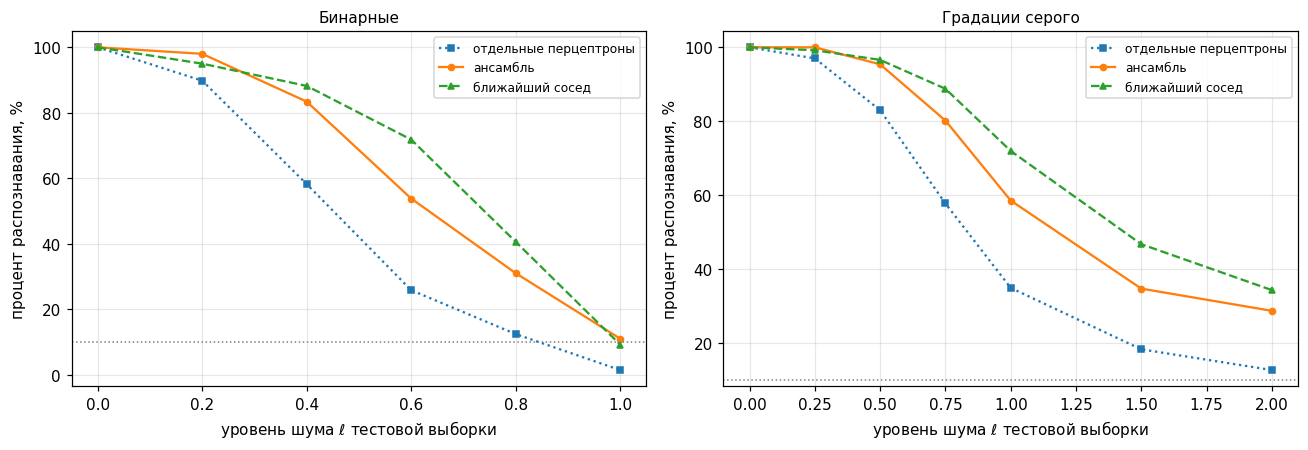

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, itype in zip(axes, IMAGE_TYPES):
    for name, style in zip(METHODS, [":s", "-o", "--^"]):
        s = res[(res["тип"] == TYPE_NAMES[itype]) & (res["метод"] == name)]
        ax.plot(s["ℓ"], s["точность, %"], style, ms=4, label=name)
    ax.axhline(10, color="gray", ls=":", lw=1)
    ax.set_xlabel("уровень шума $\\ell$ тестовой выборки")
    ax.set_ylabel("процент распознавания, %")
    ax.set_title(TYPE_NAMES[itype].capitalize(), fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
# Отказы отдельных перцептронов: ни одного или несколько ответов +1
X_, y_ = test[("gray", 1.0)]
n_pos = (perceptron_outputs(WS["gray"], X_) == 1).sum(1)
show(pd.DataFrame([np.bincount(n_pos)], index=["изображений"]).rename_axis(columns="ответов +1"),
     "Градации серого, ℓ = 1: число перцептронов с ответом +1")

extra = res[res["метод"] == "отдельные перцептроны"].set_index(["тип", "ℓ"])[["отказов, %"]]
extra["ансамбль без деления на ‖w_c‖, %"] = [100 * np.mean(np.argmax(augment(X) @ WS[itype].T, axis=1) == y)
                                           for (itype, level), (X, y) in test.items()]
extra["ансамбль, %"] = res[res["метод"] == "ансамбль"]["точность, %"].values
show(extra, "Отказы отдельных перцептронов и роль деления на ‖w_c‖")

ответов +1,0,1,2,3
изображений,221,241,36,2


### 4.1. Сравнение на задаче «эта цифра / другая цифра»

Ансамбль и метод ближайшего соседа тоже отвечают на вопрос «это цифра $c$?»: ответ $+1$, если предсказан класс $c$.
Сравниваем их с перцептроном цифры $c$ по долям из п. 3.2, усреднённым по 10 цифрам.

In [12]:
single_mean = single.groupby(["тип", "ℓ"])[["свои +1, %", "чужие +1, %"]].mean().assign(метод="перцептрон цифры c")
cmp = pd.concat([single_mean.reset_index(), res[res["метод"] != "отдельные перцептроны"]])
order = ["перцептрон", "ансамбль", "ближайший сосед"]
show(cmp.pivot_table(index=["тип", "ℓ"], columns="метод", values=["свои +1, %", "чужие +1, %"]).reindex(columns=order, level=1),
     "Задача «эта цифра / другая», среднее по 10 цифрам")

## 5. Выводы

* **Сходимость.** Все 20 перцептронов сошлись за 2–44 прохода без ошибок на обучающей выборке, то есть классы «эта цифра / другая» в ней линейно-отделимы. Больше всего исправлений у похожих цифр 3, 5, 6, 8 (48–117), меньше всего у 1, 4, 7 (2–9).
* **Отдельный перцептрон** почти не принимает чужие цифры за свою (не более 1,7 % у бинарных и 4,2 % у полутоновых), но с ростом шума перестаёт узнавать свою: 62,6 % при $\ell = 0{,}4$ (бинарные) и 65,8 % при $\ell = 0{,}75$ (полутоновые). Хуже всех распознаётся 6 (34–36 %), лучше всех 4 (100 %).
* **Отдельные перцептроны как классификатор 10 цифр** часто не дают ответа: при $\ell = 1$ у полутоновых ни один перцептрон не выдал $+1$ для 221 из 500 изображений, несколько — для 38. Отказов 37,2 % у бинарных при $\ell = 0{,}4$ и 51,8 % у полутоновых при $\ell = 1$, точность 58,2 % и 35,0 %.
* **Ансамбль** отвечает всегда и точнее отдельных перцептронов на всех уровнях шума: 83,4 % против 58,2 % (бинарные, $\ell = 0{,}4$), 58,6 % против 35,0 % (полутоновые, $\ell = 1$). Деление на $\|w_c\|$ важно для бинарных: при $\ell = 0{,}6$ — 53,8 % против 44,8 % без него, у полутоновых разница не больше 2 п. п.
* **Ансамбль против ближайшего соседа.** При слабом шуме ансамбль не хуже: 98,0 % против 95,0 % (бинарные, $\ell = 0{,}2$), 100 % против 99,2 % (полутоновые, $\ell = 0{,}25$). При сильном шуме лучше ближайший сосед: 71,8 % против 53,8 % (бинарные, $\ell = 0{,}6$), 72,0 % против 58,6 % (полутоновые, $\ell = 1$), так как перцептрон описывает цифру одной гиперплоскостью, а метод ближайшего соседа использует всю выборку.
* **Задача «эта цифра / другая».** Ансамбль узнаёт свою цифру чаще отдельного перцептрона (83,4 % против 62,6 % у бинарных при $\ell = 0{,}4$), но чаще принимает чужие за свою (5,1 % против 1,2 % при $\ell = 0{,}6$): он обязан выбрать одну из цифр. При $\ell = 1$ бинарное изображение полностью случайно, и все методы дают около 10 %.